# **Predicting heart disease using machine learning**

This notebook looks into using various python based machine learning and data science libraries in an attempt to build a machine learning model, capable of predicting whether someone has heart disease based on their medical records.

**We will take the following approach:**
1. Problem definition
2. Data
3. Evaluation
4. Features
5. Modelling
6. Experimentation

## 1. Problem Definition

Given clinical parameters about a patient, can we predict whether they have heart disease or not?

## 2. Data

The original data came from the Cleveland, VA Long Beach, Hungary and Switzerland data from the UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/45/heart+diseasehttps://archive.ics.uci.edu/dataset/45/heart+disease 

There is also a version of it available in Kaggle. The Kaggle version was used. https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data

## 3. Evaluation

Checking whether we can reach **95% accuracy** at predicting whether or not a patient has heart disease

## 4. Features

This is where we will get different information about each of the features in the data 

**Data Dictionary:**
* age (Age of the patient in years)
* sex (Male=1, Female=0)
* cp chest pain type ([typical angina, atypical angina, non-anginal, asymptomatic])
* trestbps resting blood pressure (resting blood pressure (in mm Hg on admission to the hospital))
* chol (serum cholesterol in mg/dl)
* fbs (if fasting blood sugar > 120 mg/dl)
* restecg (resting electrocardiographic results)
* thalach: maximum heart rate achieved
* exang: exercise-induced angina (True/ False)
* oldpeak: ST depression induced by exercise relative to rest
* slope: the slope of the peak exercise ST segment
* ca: number of major vessels (0-3) colored by fluoroscopy
* thal: [normal; fixed defect; reversible defect]
* num: the predicted attribute

In [1]:
# Importing tools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline 

# Models from sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluations
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import RocCurveDisplay

## **Load Data**

In [2]:
df = pd.read_csv("heart-disease.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
df.shape

(303, 14)

## **EDA (Exploratory Data Analysis)**

In [4]:
df["target"].value_counts()
# 54.45% have heart disease

target
1    165
0    138
Name: count, dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [6]:
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [7]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [8]:
# Sex vs Target
df.sex.value_counts()

sex
1    207
0     96
Name: count, dtype: int64

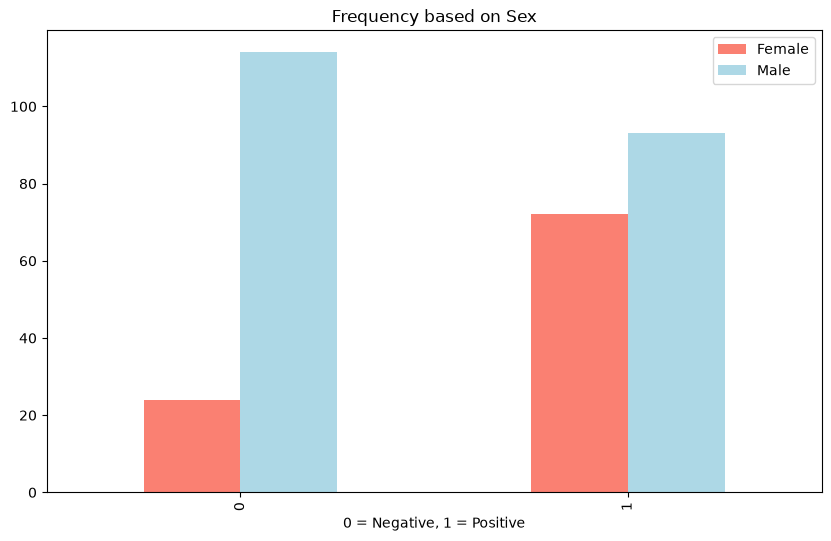

In [9]:
pd.crosstab(df.target, df.sex).plot(kind="bar", figsize=(10, 6), color=["salmon", "lightblue"])
plt.title("Frequency based on Sex")
plt.xlabel("0 = Negative, 1 = Positive")
plt.legend(["Female", "Male"]);
# 24 women don't have heart disease, whereas 72 do. (75% chance of heart disease)
# 114 men don't have heart disease, whereas 93 do. (44.92% chance of heart disease)

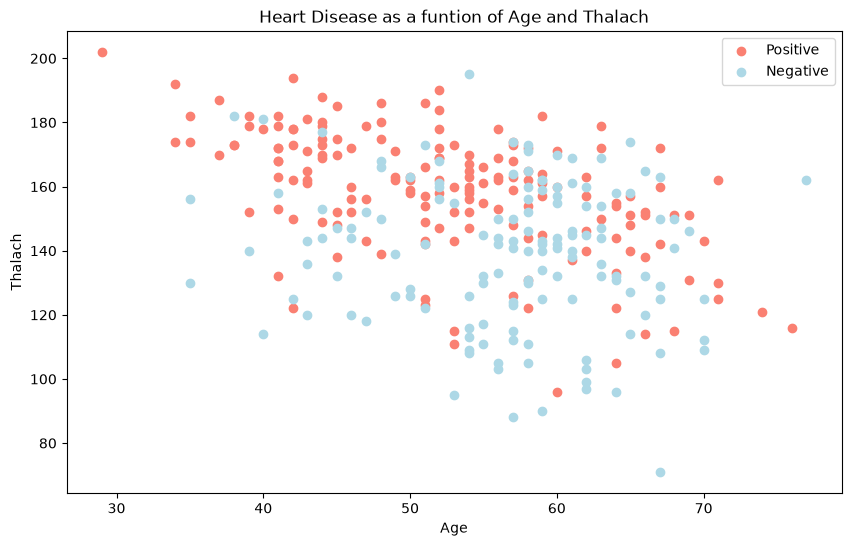

In [10]:
# Age vs Max Heart Rate (thalach)
plt.figure(figsize=(10, 6))
plt.scatter(df.age[df.target==1], df.thalach[df.target==1], c="salmon")
plt.scatter(df.age[df.target==0], df.thalach[df.target==0], c="lightblue")
plt.title("Heart Disease as a funtion of Age and Thalach")
plt.xlabel("Age")
plt.ylabel("Thalach")
plt.legend(["Positive", "Negative"]);

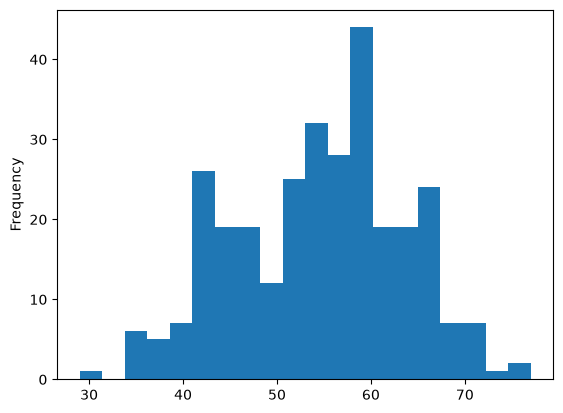

In [11]:
# Distribution of age column with histogram
df.age.plot.hist(bins=20);

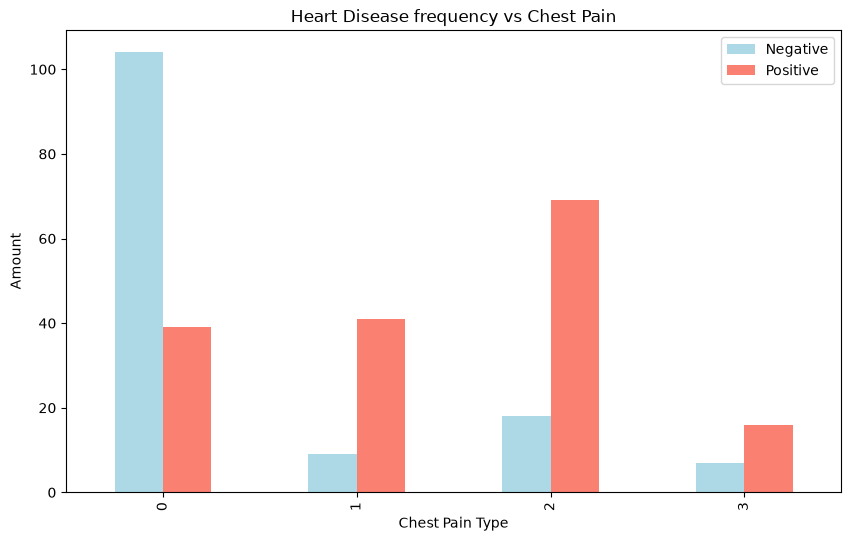

In [12]:
# Heart Disease freq vs chest pain
pd.crosstab(df.cp, df.target).plot(kind="bar", figsize=(10, 6), color=["lightblue", "salmon"])
plt.title("Heart Disease frequency vs Chest Pain")
plt.xlabel("Chest Pain Type")
plt.ylabel("Amount")
plt.legend(["Negative", "Positive"])

In [13]:
# Make a correlation matrix
df.corr()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.098447,-0.068653,0.279351,0.213678,0.121308,-0.116211,-0.398522,0.096801,0.210013,-0.168814,0.276326,0.068001,-0.225439
sex,-0.098447,1.000000,-0.049353,-0.056769,-0.197912,0.045032,-0.058196,-0.044020,0.141664,0.096093,-0.030711,0.118261,0.210041,-0.280937
cp,-0.068653,-0.049353,1.000000,0.047608,-0.076904,0.094444,0.044421,0.295762,-0.394280,-0.149230,0.119717,-0.181053,-0.161736,0.433798
trestbps,0.279351,-0.056769,0.047608,1.000000,0.123174,0.177531,-0.114103,-0.046698,0.067616,0.193216,-0.121475,0.101389,0.062210,-0.144931
chol,0.213678,-0.197912,-0.076904,0.123174,1.000000,0.013294,-0.151040,-0.009940,0.067023,0.053952,-0.004038,0.070511,0.098803,-0.085239
fbs,0.121308,0.045032,0.094444,0.177531,0.013294,1.000000,-0.084189,-0.008567,0.025665,0.005747,-0.059894,0.137979,-0.032019,-0.028046
restecg,-0.116211,-0.058196,0.044421,-0.114103,-0.151040,-0.084189,1.000000,0.044123,-0.070733,-0.058770,0.093045,-0.072042,-0.011981,0.137230
thalach,-0.398522,-0.044020,0.295762,-0.046698,-0.009940,-0.008567,0.044123,1.000000,-0.378812,-0.344187,0.386784,-0.213177,-0.096439,0.421741
exang,0.096801,0.141664,-0.394280,0.067616,0.067023,0.025665,-0.070733,-0.378812,1.000000,0.288223,-0.257748,0.115739,0.206754,-0.436757
oldpeak,0.210013,0.096093,-0.149230,0.193216,0.053952,0.005747,-0.058770,-0.344187,0.288223,1.000000,-0.577537,0.222682,0.210244,-0.430696


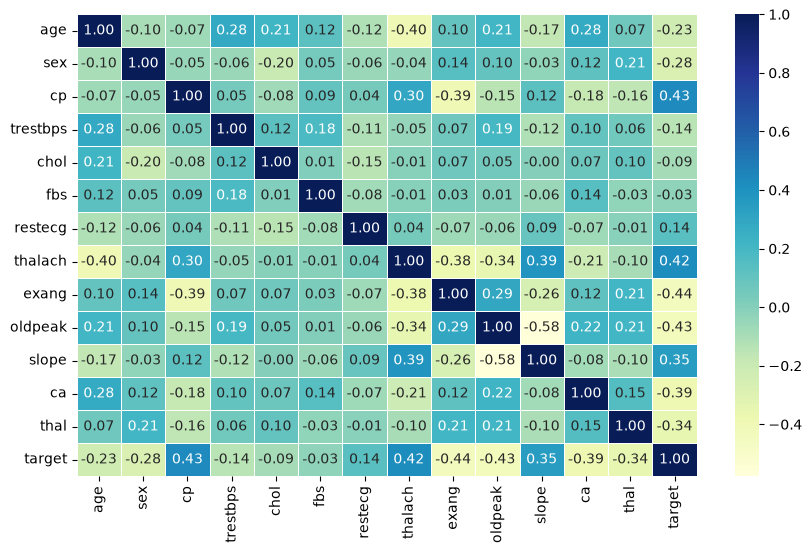

In [14]:
# Make it visual
corr_matrix = df.corr()
fig, ax = plt.subplots(figsize=(10, 6))
ax = sns.heatmap(corr_matrix,
                 annot=True,
                 linewidths=0.5,
                 fmt=".2f",
                 cmap="YlGnBu");

## **Modelling**

In [15]:
# Splitting data
X = df.drop("target", axis=1)
y = df["target"]

In [16]:
X

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3


In [17]:
y

0      1
1      1
2      1
3      1
4      1
      ..
298    0
299    0
300    0
301    0
302    0
Name: target, Length: 303, dtype: int64

In [18]:
# Splitting into train and test
np.random.seed(42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [19]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((242, 13), (61, 13), (242,), (61,))

We will try 3 different machine learning models:
1. Logistic Regression
2. K Neighbors Classifier
3. Random Forest

In [20]:
models = {"Logistic Regression": LogisticRegression(),
          "KNN": KNeighborsClassifier(),
          "Random Forest": RandomForestClassifier()}

def eval(models, X_train, X_test, y_train, y_test):
    np.random.seed(42)
    model_scores={}
    for name, model in models.items():
        model.fit(X_train, y_train)
        model_scores[name] = model.score(X_test, y_test)
    return model_scores    

In [21]:
model_scores = eval(models, X_train, X_test, y_train, y_test)
model_scores

C:\Users\Areen Valsangkar\Anaconda Projects\heart-disease-project\env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'Logistic Regression': 0.8852459016393442,
 'KNN': 0.6885245901639344,
 'Random Forest': 0.8360655737704918}

In [22]:
# Let's tune KNN

train_scores = []
test_scores = []

neighbors = range(1, 21)
knn = KNeighborsClassifier()

for i in neighbors:
    knn.set_params(n_neighbors=i)
    knn.fit(X_train, y_train)
    train_scores.append(knn.score(X_train, y_train))
    test_scores.append(knn.score(X_test, y_test))

In [23]:
train_scores

[1.0,
 0.8099173553719008,
 0.7727272727272727,
 0.743801652892562,
 0.7603305785123967,
 0.7520661157024794,
 0.743801652892562,
 0.7231404958677686,
 0.71900826446281,
 0.6942148760330579,
 0.7272727272727273,
 0.6983471074380165,
 0.6900826446280992,
 0.6942148760330579,
 0.6859504132231405,
 0.6735537190082644,
 0.6859504132231405,
 0.6652892561983471,
 0.6818181818181818,
 0.6694214876033058]

In [24]:
test_scores

[0.6229508196721312,
 0.639344262295082,
 0.6557377049180327,
 0.6721311475409836,
 0.6885245901639344,
 0.7213114754098361,
 0.7049180327868853,
 0.6885245901639344,
 0.6885245901639344,
 0.7049180327868853,
 0.7540983606557377,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.6885245901639344,
 0.7213114754098361,
 0.6885245901639344,
 0.6885245901639344,
 0.7049180327868853,
 0.6557377049180327]

Maximum KNN test score: 75.41%


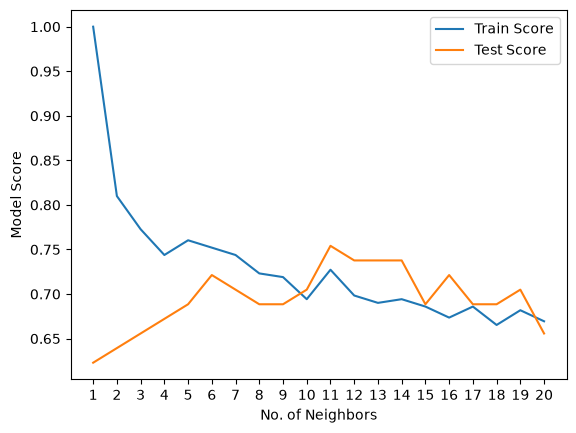

In [25]:
plt.plot(neighbors, train_scores, label="Train Score")
plt.plot(neighbors, test_scores, label="Test Score")
plt.xlabel("No. of Neighbors")
plt.xticks(np.arange(1, 21, 1))
plt.ylabel("Model Score")
plt.legend()

print(f"Maximum KNN test score: {max(test_scores)*100:.2f}%")

In [26]:
# KNN has been ruled out.
# Trying RandomizedSearchCV on Logistic Regression and Random Forest

# Hyperparameter grid for Logistic Regression
log_reg_grid = {"C": np.logspace(-4, 4, 50),
                "solver": ["liblinear"]}

# Hyperparameter grid for Random Forest
ran_for_grid = {"n_estimators": np.arange(10, 1000, 50),
                "max_depth": [None, 3, 5, 10],
                "min_samples_split": np.arange(2, 20, 2),
                "min_samples_leaf": np.arange(1, 20, 2)}

In [27]:
# For Logistic Regression
np.random.seed(42)

rs_log_reg = RandomizedSearchCV(LogisticRegression(),
                                param_distributions=log_reg_grid,
                                cv=5,
                                n_iter=20,
                                verbose=2)

rs_log_reg.fit(X_train, y_train);

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END ...........C=0.013257113655901081, solver=liblinear; total time=   0.0s
[CV] END ...........C=0.013257113655901081, solver=liblinear; total time=   0.0s
[CV] END ...........C=0.013257113655901081, solver=liblinear; total time=   0.0s
[CV] END ...........C=0.013257113655901081, solver=liblinear; total time=   0.0s
[CV] END ...........C=0.013257113655901081, solver=liblinear; total time=   0.0s
[CV] END .............C=232.99518105153672, solver=liblinear; total time=   0.0s
[CV] END .............C=232.99518105153672, solver=liblinear; total time=   0.0s
[CV] END .............C=232.99518105153672, solver=liblinear; total time=   0.0s
[CV] END .............C=232.99518105153672, solver=liblinear; total time=   0.0s
[CV] END .............C=232.99518105153672, solver=liblinear; total time=   0.0s
[CV] END .............C=7.9060432109076855, solver=liblinear; total time=   0.0s
[CV] END .............C=7.9060432109076855, sol

In [28]:
rs_log_reg.best_params_

{'solver': 'liblinear', 'C': np.float64(0.12648552168552957)}

In [29]:
rs_log_reg.score(X_test, y_test)

0.8852459016393442

In [30]:
# For Random Forest
np.random.seed(42)

rs_ran_for = RandomizedSearchCV(RandomForestClassifier(),
                                param_distributions=ran_for_grid,
                                cv=5,
                                n_iter=50,
                                verbose=2)

rs_ran_for.fit(X_train, y_train);

Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END max_depth=None, min_samples_leaf=9, min_samples_split=16, n_estimators=10; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=9, min_samples_split=16, n_estimators=10; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=9, min_samples_split=16, n_estimators=10; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=9, min_samples_split=16, n_estimators=10; total time=   0.0s
[CV] END max_depth=None, min_samples_leaf=9, min_samples_split=16, n_estimators=10; total time=   0.0s
[CV] END max_depth=5, min_samples_leaf=19, min_samples_split=18, n_estimators=510; total time=   1.0s
[CV] END max_depth=5, min_samples_leaf=19, min_samples_split=18, n_estimators=510; total time=   0.9s
[CV] END max_depth=5, min_samples_leaf=19, min_samples_split=18, n_estimators=510; total time=   0.9s
[CV] END max_depth=5, min_samples_leaf=19, min_samples_split=18, n_estimators=510; total time=   0.8s
[CV] END max_de

In [31]:
rs_ran_for.best_params_

{'n_estimators': np.int64(260),
 'min_samples_split': np.int64(16),
 'min_samples_leaf': np.int64(17),
 'max_depth': 3}

In [32]:
rs_ran_for.score(X_test, y_test)

0.8688524590163934

In [33]:
# Using GridSearchCV on logistic regression.
lr_grid = [
    {
        'solver': ['liblinear'],
        'l1_ratio': [0.0, 1.0], # Use 'penalty': ['l1', 'l2'] if on older sklearn
        'C': np.logspace(-4, 4, 20),
        'class_weight': [None, 'balanced']
    },
    {
        'solver': ['saga'],
        'l1_ratio': [0.0, 0.5, 1.0],
        'C': np.logspace(-4, 4, 20),
        'class_weight': [None, 'balanced']
    }
]

gs_lr = GridSearchCV(LogisticRegression(),
                      param_grid=log_reg_grid,
                      cv=5,
                      verbose=2)

gs_lr.fit(X_train, y_train);

Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END .........................C=0.0001, solver=liblinear; total time=   0.0s
[CV] END .........................C=0.0001, solver=liblinear; total time=   0.0s
[CV] END .........................C=0.0001, solver=liblinear; total time=   0.0s
[CV] END .........................C=0.0001, solver=liblinear; total time=   0.0s
[CV] END .........................C=0.0001, solver=liblinear; total time=   0.0s
[CV] END .........C=0.00014563484775012445, solver=liblinear; total time=   0.0s
[CV] END .........C=0.00014563484775012445, solver=liblinear; total time=   0.0s
[CV] END .........C=0.00014563484775012445, solver=liblinear; total time=   0.0s
[CV] END .........C=0.00014563484775012445, solver=liblinear; total time=   0.0s
[CV] END .........C=0.00014563484775012445, solver=liblinear; total time=   0.0s
[CV] END .........C=0.00021209508879201905, solver=liblinear; total time=   0.0s
[CV] END .........C=0.00021209508879201905, sol

In [34]:
gs_lr.best_params_

{'C': np.float64(0.18420699693267145), 'solver': 'liblinear'}

In [35]:
gs_lr.score(X_test, y_test)

0.8852459016393442

No change :(

## **Evaluation other than accuracy**

In [36]:
# Predictions using trained model
y_preds = gs_lr.predict(X_test)

In [37]:
y_preds

array([0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0,
       0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0])

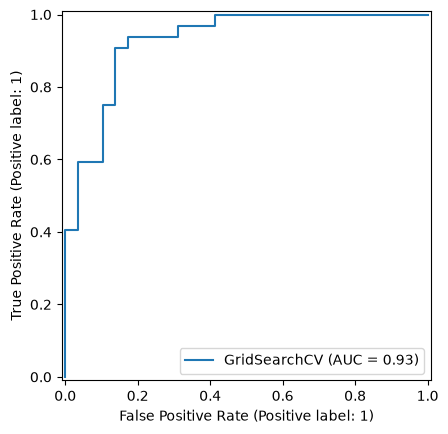

In [38]:
# ROC-AUC 
RocCurveDisplay.from_estimator(gs_lr, X_test, y_test);

In [39]:
# Confusion matrix
print(confusion_matrix(y_test, y_preds))

[[25  4]
 [ 3 29]]


Text(-3.072794596354166, 0.5, 'True label')

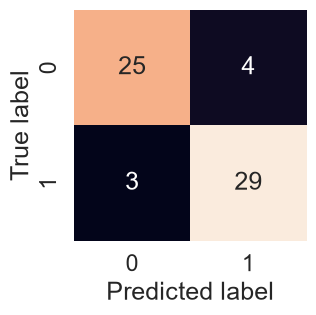

In [40]:
sns.set(font_scale=1.5)

fig, ax = plt.subplots(figsize=(3, 3))
ax = sns.heatmap(confusion_matrix(y_test, y_preds),
                 annot=True,
                 cbar=False)
plt.xlabel("Predicted label")
plt.ylabel("True label")

In [41]:
# Classification report
print(classification_report(y_test, y_preds))

              precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.88      0.91      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.88      0.88        61
weighted avg       0.89      0.89      0.89        61



In [42]:
# Cross validation:
clf = LogisticRegression(C=0.18420699693267145, solver="liblinear")

In [43]:
# CV Accuracy
cv_acc = cross_val_score(clf, X, y, cv=5, scoring="accuracy").mean()
print(cv_acc)

0.8446994535519124


In [44]:
# CV Precision
cv_prec = cross_val_score(clf, X, y, cv=5, scoring="precision").mean()
print(cv_prec)

0.8207936507936507


In [45]:
# CV Recall
cv_rec = cross_val_score(clf, X, y, cv=5, scoring="recall").mean()
print(cv_rec)

0.9212121212121213


In [46]:
# CV F1
cv_f1 = cross_val_score(clf, X, y, cv=5, scoring="f1").mean()
print(cv_f1)

0.8673007976269721


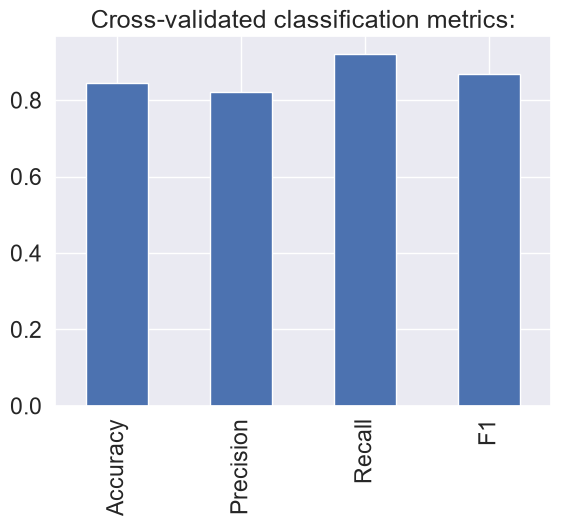

In [47]:
cv_metrics = pd.DataFrame({"Accuracy": cv_acc, 
                           "Precision": cv_prec, 
                           "Recall": cv_rec,
                           "F1": cv_f1},
                         index=[0])

cv_metrics.T.plot.bar(title="Cross-validated classification metrics:",
                      legend=False);

## Feature Importance

In [48]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [49]:
clf = LogisticRegression(C=0.18420699693267145, solver="liblinear")
clf.fit(X_train, y_train);

In [50]:
# Check coef
clf.coef_

array([[ 0.00274534, -0.82466189,  0.64946587, -0.01155522, -0.00162953,
         0.04067028,  0.29769479,  0.02448922, -0.58200187, -0.56321728,
         0.43464708, -0.62480489, -0.66201556]])

In [51]:
# Match feature names to their learned weights
feature_dict = dict(zip(df.columns, list(clf.coef_[0])))
feature_dict

{'age': np.float64(0.0027453388946929187),
 'sex': np.float64(-0.824661890588809),
 'cp': np.float64(0.6494658744531004),
 'trestbps': np.float64(-0.011555217578049105),
 'chol': np.float64(-0.0016295281892291802),
 'fbs': np.float64(0.040670283694531004),
 'restecg': np.float64(0.29769479242008245),
 'thalach': np.float64(0.02448921764656036),
 'exang': np.float64(-0.5820018686153617),
 'oldpeak': np.float64(-0.5632172849700932),
 'slope': np.float64(0.43464707836362726),
 'ca': np.float64(-0.6248048892031132),
 'thal': np.float64(-0.6620155629137882)}

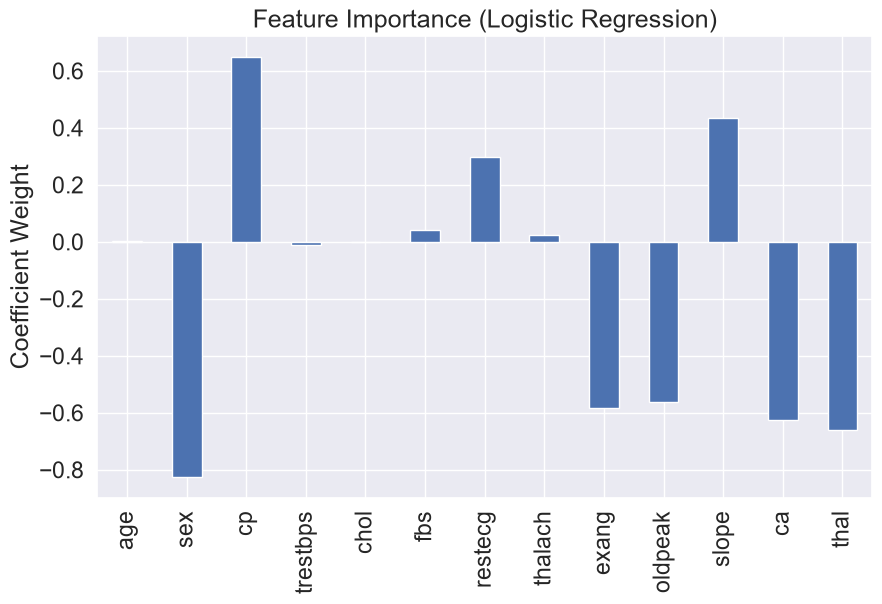

In [52]:
feature_df = pd.DataFrame(feature_dict, index=[0])
feature_df.T.plot.bar(
    title="Feature Importance (Logistic Regression)",
    legend=False,
    figsize=(10, 6),
)
plt.ylabel("Coefficient Weight")
plt.show()

## **Experimentation**

In [53]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

### **Scaling and One Hot Encoding Logistic Regression Pipeline:**

In [54]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
cat_cols = ["cp", "restecg", "slope", "thal"]

In [55]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first"), cat_cols),
    ],
    remainder="passthrough",
)

In [56]:
pipe_log_reg = Pipeline([
    ("preprocessor", preprocessor),
    (
        "clf",
        LogisticRegression(
            C=rs_log_reg.best_params_["C"],
            solver="liblinear",
            max_iter=1000,
        ),
    ),
])

In [57]:
pipe_log_reg.fit(X_train, y_train)
print(f"Preprocessed Logistic Regression Accuracy: {pipe_log_reg.score(X_test, y_test) * 100:.2f}%")

Preprocessed Logistic Regression Accuracy: 90.16%


### **Gradient Boosting Classifier (with Hyperparameter Tuning):**

In [58]:
gb_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "subsample": [0.8, 1.0],
}

In [59]:
np.random.seed(42)

rs_gb = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_distributions=gb_grid,
    cv=5,
    n_iter=20,
    verbose=1,
    random_state=42,
)

In [60]:
rs_gb.fit(X_train, y_train)
print(f"Best GB Params: {rs_gb.best_params_}")
print(f"Gradient Boosting Accuracy: {rs_gb.score(X_test, y_test) * 100:.2f}%")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best GB Params: {'subsample': 1.0, 'n_estimators': 50, 'max_depth': 2, 'learning_rate': 0.05}
Gradient Boosting Accuracy: 81.97%


### **Comparing:**

In [61]:
models_to_compare = {
    "Preprocessed Logistic Regression": pipe_log_reg,
    "Tuned Gradient Boosting": rs_gb.best_estimator_,
}

for name, model in models_to_compare.items():
    cv_acc = np.mean(cross_val_score(model, X, y, cv=5, scoring="accuracy"))
    cv_prec = np.mean(cross_val_score(model, X, y, cv=5, scoring="precision"))
    cv_recall = np.mean(cross_val_score(model, X, y, cv=5, scoring="recall"))
    cv_f1 = np.mean(cross_val_score(model, X, y, cv=5, scoring="f1"))

    print(name+":")
    print(f"5-Fold CV Accuracy : {cv_acc * 100:.2f}%")
    print(f"5-Fold CV Precision: {cv_prec*100:.2f}%")
    print(f"5-Fold CV Recall   : {cv_recall * 100:.2f}%")
    print(f"5-Fold CV F1-Score : {cv_f1 * 100:.2f}%\n")
    print()

Preprocessed Logistic Regression:
5-Fold CV Accuracy : 82.16%
5-Fold CV Precision: 82.31%
5-Fold CV Recall   : 86.06%
5-Fold CV F1-Score : 84.05%


Tuned Gradient Boosting:
5-Fold CV Accuracy : 82.49%
5-Fold CV Precision: 81.28%
5-Fold CV Recall   : 89.09%
5-Fold CV F1-Score : 84.84%




## **Saving the model**

Since pipeline and scaled model is marginally better, we will save it.

In [62]:
import joblib

joblib.dump(pipe_log_reg, "heart_disease_project_model.joblib")

['heart_disease_project_model.joblib']

## **Importing the model**

Then testing it:

In [63]:
loaded_model = joblib.load("heart_disease_project_model.joblib")

new_patient = pd.DataFrame([{
    "age": 54,
    "sex": 1,
    "cp": 0,
    "trestbps": 140,
    "chol": 239,
    "fbs": 0,
    "restecg": 1,
    "thalach": 160,
    "exang": 0,
    "oldpeak": 1.2,
    "slope": 2,
    "ca": 0,
    "thal": 2,
}])

print(loaded_model.predict(new_patient)[0])

1


In [64]:
print(loaded_model.predict_proba(new_patient)[0][1])

0.7552786092170914


### **Testing on new dataset:**

In [65]:
test_df = pd.read_csv("heart_disease_uci.csv")
test_df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


#### We will drop data from the cleveland dataset (since our training and testing was done on Cleveland itself), and then map values so that it is similar to original dataset.

In [66]:
ext_df = test_df[test_df["dataset"] != "Cleveland"].copy()
ext_df = ext_df.drop(columns=["id", "dataset"])
ext_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
304,29,Male,atypical angina,120.0,243.0,False,normal,160.0,False,0.0,NaN,NaN,NaN,0
305,29,Male,atypical angina,140.0,NaN,False,normal,170.0,False,0.0,NaN,NaN,NaN,0
306,30,Female,typical angina,170.0,237.0,False,st-t abnormality,170.0,False,0.0,NaN,NaN,fixed defect,0
307,31,Female,atypical angina,100.0,219.0,False,st-t abnormality,150.0,False,0.0,NaN,NaN,NaN,0
308,32,Female,atypical angina,105.0,198.0,False,normal,165.0,False,0.0,NaN,NaN,NaN,0


#### Mapping:

In [67]:
ext_df["sex"] = ext_df["sex"].map({"Male": 1, "Female": 0})

In [68]:
ext_df["cp"] = ext_df["cp"].map({
    "asymptomatic": 0,
    "atypical angina": 1,
    "non-anginal": 2,
    "typical angina": 3,
})

In [69]:
ext_df["fbs"] = ext_df["fbs"].map({True: 1, False: 0, "True": 1, "False": 0})
ext_df["exang"] = ext_df["exang"].map(
    {True: 1, False: 0, "True": 1, "False": 0}
)

In [70]:
ext_df["restecg"] = ext_df["restecg"].map({
    "normal": 1,
    "lv hypertrophy": 0,
    "st-t abnormality": 2,
})

In [71]:
ext_df["slope"] = ext_df["slope"].map({
    "downsloping": 0,
    "flat": 1,
    "upsloping": 2,
})

In [72]:
ext_df["thal"] = ext_df["thal"].map({
    "fixed defect": 1,
    "normal": 2,
    "reversable defect": 3,
    "reversible defect": 3,
})

In [73]:
# Convert target column ('num': 0 vs 1-4) into binary 'target' (0 or 1)
target_col = "num" if "num" in ext_df.columns else "target"
ext_df["target"] = (ext_df[target_col] == 0).astype(int)
if target_col == "num":
  ext_df = ext_df.drop(columns=["num"])

In [74]:
len(ext_df)

616

In [75]:
ext_df.isna().sum()

age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       308
ca          606
thal        483
target        0
dtype: int64

#### SO MANY MISSING VALUES!

In [76]:
# 0 cholestrol as NaN
ext_df["chol"] = ext_df["chol"].replace(0, np.nan)

In [77]:
ext_df = ext_df.rename(columns={"thalch": "thalach"})
for col in X_train.columns:
  if ext_df[col].isna().sum() > 0:
    fill_val = X_train[col].median()
    ext_df[col] = ext_df[col].fillna(fill_val)

In [78]:
X_ext = ext_df[X_train.columns]
y_ext = ext_df["target"]

In [79]:
y_ext_preds = rs_log_reg.predict(X_ext)

In [80]:
accuracy_score(y_ext, y_ext_preds)

0.7451298701298701

In [81]:
confusion_matrix(y_ext, y_ext_preds)

array([[254, 116],
       [ 41, 205]])

In [82]:
classification_report(y_ext, y_ext_preds)

'              precision    recall  f1-score   support\n\n           0       0.86      0.69      0.76       370\n           1       0.64      0.83      0.72       246\n\n    accuracy                           0.75       616\n   macro avg       0.75      0.76      0.74       616\nweighted avg       0.77      0.75      0.75       616\n'

#### **We got a lower metric score since the Hungarian, Switzerland and VA Long Island datasets have a lot of missing values in ca and thal. These were two of the strongest predictors in my original model**

## 7. Conclusion

### Did we reach our evaluation goal?
At the start of the notebook, the goal was to hit **95% accuracy**. After testing and tuning multiple models, the highest score reached on the Cleveland dataset was **~88.5%** with Logistic Regression. On a small clinical dataset of 303 patients, hitting 95% without overfitting isn't really realistic because of natural noise in medical records, so ~88.5% is a solid result.

### Key Takeaways
* **Best Model:** Tuned **Logistic Regression** performed the best overall (~88.5% accuracy), outperforming both KNN (~75.4%) and Random Forest (~83.6%).
* **Most Important Features:** Chest pain type `cp`, maximum heart rate `thalach`, exercise-induced angina `exang`, ST depression `oldpeak`, and major vessels `ca` had the biggest impact on predictions.
* **Testing on External Hospitals:** When testing the trained model on the remaining 616 rows (Hungary, Switzerland, and VA Long Beach), accuracy dropped to **~74.0%**. As seen earlier, those datasets are missing a huge chunk of values for `ca` and `thal`—which were two of the strongest predictors in my model—so imputing them with median values naturally lowered the score.

### What I could do next
* Save the trained pipeline using `joblib` and build a simple web app (like Streamlit) where you can input patient values and get a prediction.
* Focus more on **Recall** rather than just accuracy, since in a medical context, missing someone who actually has heart disease is much worse than a false alarm.